# 03 · Customer segmentation with clustering

**Goal:** let an algorithm find groups of similar customers, describe them in business terms
and compare them with the rule-based RFM segments of phase 2.

In phase 2 the segments were defined by fixed rules on 1–5 scores. Here k-means works on the
actual recency, frequency and monetary values, so it can find boundaries the rules miss.
Where the two segmentations agree, they confirm each other; where they disagree, there is
something worth looking at.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src import segmentation as seg
from src.rfm import SEGMENT_ORDER

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

rfm = pd.read_parquet(PROCESSED_DIR / "rfm.parquet")
print(f"{len(rfm):,} customers, random state {seg.RANDOM_STATE}")

BLUE, ORANGE, TEXT, MUTED, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

def style_axis(ax):
    """Light, recessive axes so the data stands out."""
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED, labelsize=9)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

5,839 customers, random state 42


## Features: log transform and standardisation

K-means assigns each customer to the nearest cluster centre, so everything depends on how
distance is measured. Two problems have to be fixed first.

**1. Skew.** A few customers have hundreds of invoices and hundreds of thousands of pounds. On the
raw scale they are so far from everyone else that they would get a cluster almost to themselves,
while the bulk of the customers would be squeezed together. The log transform compresses large
values (10, 100 and 1,000 become 1, 2 and 3 in base 10) while keeping their order.

In [2]:
features = seg.build_features(rfm)

skew = pd.DataFrame({
    "raw": rfm[["recency", "frequency", "monetary"]].skew().values,
    "log": features.skew().values,
}, index=["recency", "frequency", "monetary"])
skew.round(2)

,raw,log
recency,0.89,-0.55
frequency,11.96,0.62
monetary,26.79,0.12


Skewness is 0 for a symmetric distribution. After the log, all three features are close to
symmetric. The 7 customers with net spend of zero or less are clipped to 0 before `log1p`.

**2. Different units.** Days, number of invoices and pounds live on different scales. K-means adds
up the differences on all features, so the one with the largest numbers would dominate. Each
feature is therefore standardised to mean 0 and standard deviation 1.

In [3]:
scaler = StandardScaler()
X = scaler.fit_transform(features)
pd.DataFrame(X, columns=features.columns).describe().loc[["mean", "std"]].round(2)

,log_recency,log_frequency,log_monetary
mean,-0.0,0.0,0.0
std,1.0,1.0,1.0


## Choosing the number of clusters

K-means needs `k` in advance. Three pieces of evidence are combined:

- **Inertia** (within-cluster distance): always decreases with more clusters; an "elbow" suggests
  where extra clusters stop helping.
- **Silhouette**: for each customer, how much closer it is to its own cluster than to the next one,
  averaged over all customers (from -1 to 1, higher is better).
- **Business usefulness**: a marketing team can act on a handful of clearly different groups.

The BIC of a Gaussian mixture (GMM) is computed at the same time and discussed below.

In [4]:
k_values = range(2, 11)
scores = seg.evaluate_k(X, k_values)
scores.round(3)

,inertia,silhouette,gmm_bic
k,,,
2,8508.147,0.434,37596.542
3,6337.869,0.343,20367.419
4,4938.642,0.363,19649.655
5,4180.518,0.334,19393.788
6,3617.159,0.335,10093.466
7,3262.461,0.303,9649.634
8,2959.672,0.296,3732.889
9,2734.108,0.286,-3447.856
10,2535.585,0.293,2392.526


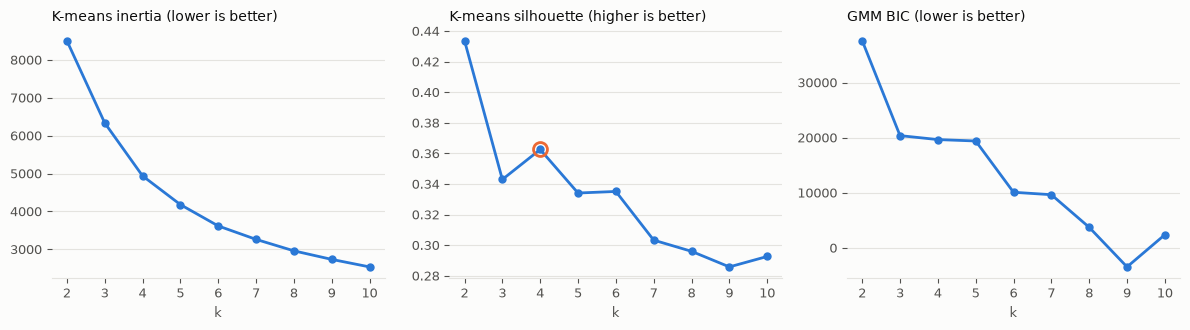

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), facecolor=SURFACE)
panels = [("inertia", "K-means inertia (lower is better)"),
          ("silhouette", "K-means silhouette (higher is better)"),
          ("gmm_bic", "GMM BIC (lower is better)")]

for ax, (col, title) in zip(axes, panels):
    ax.plot(scores.index, scores[col], color=BLUE, linewidth=2, marker="o", markersize=5)
    ax.set_title(title, loc="left", color=TEXT, fontsize=10)
    ax.set_xticks(list(k_values))
    ax.set_xlabel("k", color=MUTED, fontsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    style_axis(ax)

axes[1].plot(4, scores.loc[4, "silhouette"], marker="o", markersize=10, markerfacecolor="none",
             markeredgecolor=ORANGE, markeredgewidth=2)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_choosing_k.png", dpi=150, facecolor=SURFACE)
plt.show()

- The **silhouette** is highest at k = 2, but two groups ("good" and "bad" customers) are not
  useful for marketing. After that it has a second peak at **k = 4** (circled), higher than k = 3.
- The **inertia** has no sharp elbow, which is common with real customer data.

The other requirement is **stability**: k-means starts from random centres, so a good solution
should not change when the seed changes. The adjusted Rand index (ARI) compares two labelings,
ignoring cluster numbers: 1 means identical groups.

In [6]:
stability = pd.Series({k: seg.stability(X, k) for k in (3, 4, 5, 6)}, name="min ARI across 5 seeds")
stability.round(3)

3    0.969
4    0.993
5    0.925
6    0.981
Name: min ARI across 5 seeds, dtype: float64

k = 4 has a good silhouette, is almost perfectly stable across seeds and, as shown below, gives four
groups that each have a clear business meaning. It is the chosen solution.

## Why not a Gaussian mixture?

A GMM is a more flexible alternative: clusters can be elongated ellipses instead of spheres, and
each customer gets a probability of belonging to each cluster. The number of components is usually
chosen with the BIC. Here, however, the BIC drops in large jumps all the way to k = 9 and never points
to a small, usable number of segments. The reason is that frequency takes only a few integer values for
most customers:

In [7]:
print("Customers with exactly 1, 2, 3 invoices:",
      rfm["frequency"].value_counts().loc[[1, 2, 3]].to_dict())

gmm_9 = GaussianMixture(n_components=9, covariance_type="full", n_init=3,
                        random_state=seg.RANDOM_STATE).fit(X)
components = pd.DataFrame({
    "customers": np.bincount(gmm_9.predict(X), minlength=9),
    "frequency_variance": gmm_9.covariances_[:, 1, 1],
    "typical_frequency": np.exp(scaler.inverse_transform(gmm_9.means_)[:, 1]).round(1),
})
components.sort_values("customers", ascending=False)

Customers with exactly 1, 2, 3 invoices: {1: 1613, 2: 952, 3: 665}


,customers,frequency_variance,typical_frequency
0,1613,0.000001,1.0
4,1007,0.108145,10.1
8,950,0.000001,2.0
7,665,0.000001,3.0
3,477,0.000001,4.0
1,354,0.000001,5.0
6,353,0.014322,6.7
2,337,0.272794,20.9
5,83,0.990970,27.1


Several components sit exactly on one frequency value (1, 2, 3 invoices…) with a variance equal to
the minimum allowed (`1e-6`). A Gaussian squeezed onto a single value has an enormous density, and the
BIC rewards it, even though "customers with exactly 2 invoices" is not a meaningful segment.

The GMM with 4 components also disagrees substantially with k-means and is uncertain about many customers:

In [8]:
gmm_4 = GaussianMixture(n_components=4, covariance_type="full", n_init=3,
                        random_state=seg.RANDOM_STATE).fit(X)
kmeans_4 = seg.fit_kmeans(X, 4)

print(f"Agreement with k-means (ARI): {adjusted_rand_score(kmeans_4.labels_, gmm_4.predict(X)):.2f}")
print(f"Customers whose highest GMM probability is below 0.8: "
      f"{(gmm_4.predict_proba(X).max(axis=1) < 0.8).mean():.0%}")

Agreement with k-means (ARI): 0.40
Customers whose highest GMM probability is below 0.8: 29%


K-means is kept: its clusters are stable, its assumptions do not break on the integer frequency,
and it is easier to explain to a marketing team ("each customer belongs to the closest typical profile").

## The four clusters

K-means numbers clusters arbitrarily, so they are reordered from the lowest to the highest median
spend and then named after looking at their profile.

In [9]:
CLUSTER_NAMES = ["Lost one-timers", "Recent, low frequency", "Fading regulars", "Best customers"]

clusters = seg.order_by_value(kmeans_4.labels_, rfm["monetary"])
rfm["cluster"] = pd.Categorical.from_codes(clusters, categories=CLUSTER_NAMES)

profile = seg.profile_clusters(rfm, rfm["cluster"])
profile.style.format({
    "customers": "{:,}", "median_recency": "{:.0f}", "median_frequency": "{:.0f}",
    "median_monetary": "£{:,.0f}", "share_of_customers": "{:.1%}", "share_of_revenue": "{:.1%}",
})

,customers,median_recency,median_frequency,median_monetary,share_of_customers,share_of_revenue
cluster,,,,,,
Lost one-timers,"1,945",398,1,£254,33.3%,3.6%
"Recent, low frequency","1,165",24,3,£725,20.0%,5.9%
Fading regulars,"1,517",188,4,"£1,342",26.0%,16.4%
Best customers,"1,212",17,13,"£4,711",20.8%,74.1%


The names must match the numbers, so they are checked rather than trusted:

In [10]:
p = profile
assert p["median_recency"].idxmax() == "Lost one-timers" and p.loc["Lost one-timers", "median_frequency"] == 1
assert p["median_frequency"].idxmax() == "Best customers" and p["share_of_revenue"].idxmax() == "Best customers"
assert p.loc["Recent, low frequency", "median_recency"] < p.loc["Fading regulars", "median_recency"]
assert p.loc["Fading regulars", "median_frequency"] > p.loc["Recent, low frequency", "median_frequency"]
print("Cluster names are consistent with their profiles")

Cluster names are consistent with their profiles


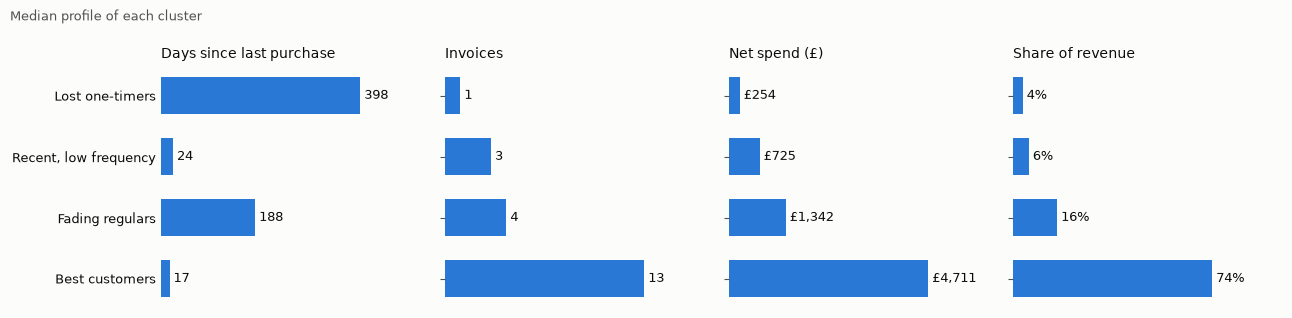

In [11]:
order = CLUSTER_NAMES[::-1]  # best customers at the top
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True, facecolor=SURFACE)
panels = [("median_recency", "Days since last purchase", "{:.0f}"),
          ("median_frequency", "Invoices", "{:.0f}"),
          ("median_monetary", "Net spend (£)", "£{:,.0f}"),
          ("share_of_revenue", "Share of revenue", "{:.0%}")]

for ax, (col, title, fmt) in zip(axes, panels):
    values = profile.loc[order, col]
    ax.barh(order, values, color=BLUE, height=0.6)
    for y, v in enumerate(values):
        ax.text(v, y, " " + fmt.format(v), va="center", color=TEXT, fontsize=9)
    ax.set_title(title, loc="left", color=TEXT, fontsize=10)
    ax.set_xticks([])
    style_axis(ax)
    ax.spines["bottom"].set_visible(False)
    ax.set_xlim(0, values.max() * 1.35)
axes[0].tick_params(axis="y", colors=TEXT, length=0)

fig.suptitle("Median profile of each cluster", x=0.01, ha="left", color=MUTED, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_cluster_profiles.png", dpi=150, facecolor=SURFACE)
plt.show()

## Business description and recommended actions

| Cluster | Who they are | Recommended action |
|---|---|---|
| **Best customers** | About a fifth of the customers, buying every few weeks, around three quarters of revenue | Protect them: account management, early access to new collections, loyalty benefits. Watch for any slowdown, since losing one costs as much as losing dozens of others |
| **Fading regulars** | Had a buying habit (several orders, over £1,000) but the last order is about six months old | The biggest opportunity: they already know and like the shop. Personalised win-back based on past purchases, a short survey, and a trigger when the gap since the last order exceeds their usual interval |
| **Recent, low frequency** | Bought in the last few weeks, only a few orders so far | Nurture towards a habit: follow-up recommendations, bundles or volume discounts, reminders before the Christmas peak |
| **Lost one-timers** | One order, more than a year ago, small basket | Low priority: cheap automated reactivation only. Worth checking whether the first order experience went wrong |

## Comparison with the RFM segments

How do the rule-based segments of phase 2 spread across the four clusters? Each row shows where the
customers of one RFM segment end up.

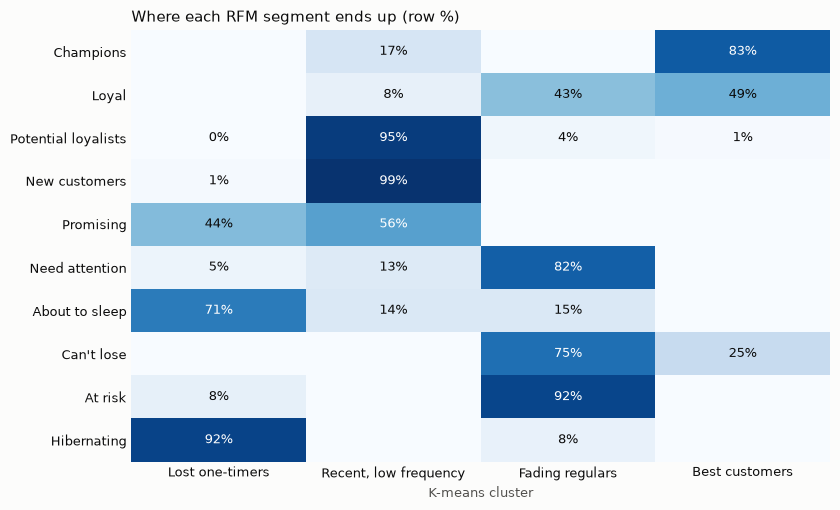

cluster,Lost one-timers,"Recent, low frequency",Fading regulars,Best customers
segment,,,,
Champions,0,137,0,685
Loyal,0,84,437,506
Potential loyalists,1,681,26,7
New customers,1,76,0,0
Promising,71,90,0,0
Need attention,15,36,230,0
About to sleep,298,61,62,0
Can't lose,0,0,43,14
At risk,53,0,593,0


In [12]:
crosstab = pd.crosstab(rfm["segment"], rfm["cluster"]).reindex(SEGMENT_ORDER)
shares = crosstab.div(crosstab.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8.5, 5.2), facecolor=SURFACE)
ax.imshow(shares.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(shares.shape[0]):
    for j in range(shares.shape[1]):
        value = shares.iloc[i, j]
        if crosstab.iloc[i, j] > 0:
            ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if value > 0.55 else TEXT)

ax.set_xticks(range(len(CLUSTER_NAMES)), CLUSTER_NAMES, fontsize=9, color=TEXT)
ax.set_yticks(range(len(SEGMENT_ORDER)), SEGMENT_ORDER, fontsize=9, color=TEXT)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel("K-means cluster", color=MUTED, fontsize=9)
ax.set_title("Where each RFM segment ends up (row %)", loc="left", color=TEXT, fontsize=11)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_rfm_vs_clusters.png", dpi=150, facecolor=SURFACE)
plt.show()

crosstab

In [13]:
loyal = rfm[rfm["segment"] == "Loyal"]
loyal.groupby("cluster", observed=True).agg(
    customers=("recency", "size"),
    median_recency=("recency", "median"),
    median_frequency=("frequency", "median"),
    median_monetary=("monetary", "median"),
).round(0)

,customers,median_recency,median_frequency,median_monetary
cluster,,,,
"Recent, low frequency",84,29.0,5.0,1186.0
Fading regulars,437,89.0,6.0,1900.0
Best customers,506,36.0,12.0,4379.0


The two methods largely agree: Champions fall mostly in Best customers, Hibernating in Lost one-timers,
At risk in Fading regulars, and New customers and Potential loyalists in Recent, low frequency.

The main disagreement is the **Loyal** segment, which splits between Best customers and Fading
regulars. In the grid, Loyal means recency score 3 or 4 (last purchase between about three weeks and six
months ago) and at least 5 invoices, so very different customers share the label. K-means works on the
actual values and separates heavy buyers who are still active (median 36 days, 12 invoices) from moderate
buyers whose last order is already three months old (median 89 days, 6 invoices).

This is the practical value of the clustering here: part of a segment that looks healthy in the RFM grid
is already losing the habit.

## Save the segments

In [14]:
rfm.to_parquet(PROCESSED_DIR / "segments.parquet")
print(f"Saved {len(rfm):,} customers with RFM segment and cluster to {PROCESSED_DIR.name}/segments.parquet")

Saved 5,839 customers with RFM segment and cluster to processed/segments.parquet


## Summary

| Choice | Decision | Reason |
|---|---|---|
| Inputs | Actual recency, frequency, monetary, not 1–5 scores | Scores discard information (10 and 369 invoices both score 5) |
| Transform | Log, then standardisation | Strong skew; features in different units would not weigh equally in distances |
| Algorithm | K-means (`n_init=10`, fixed seed) | Stable and easy to explain; GMM degenerates on the integer frequency |
| Number of clusters | k = 4 | Second-best silhouette after the trivial k = 2, ARI ≈ 0.99 across seeds, four actionable groups |
| Validation | Names checked with assertions; comparison with RFM segments | Cluster labels are arbitrary and must match the data they describe |